# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [18]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

activos_reales = ["MMM", "MRK", "IBM"]

datos = yf.download(
    activos_reales,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False)

print(datos.head())
print(datos.shape)

Price            Close                               High             \
Ticker             IBM        MMM         MRK         IBM        MMM   
Date                                                                   
2024-01-02  148.906357  86.031647  104.088928  150.556768  86.547839   
2024-01-03  147.615540  84.303185  105.495262  149.118424  85.609297   
2024-01-04  148.316254  84.600388  107.554260  149.192171  85.515447   
2024-01-05  146.748810  84.928871  107.747292  148.030418  85.632768   
2024-01-08  148.574417  85.140038  107.894348  148.648180  85.218247   

Price                          Low                               Open  \
Ticker             MRK         IBM        MMM         MRK         IBM   
Date                                                                    
2024-01-02  104.162465  147.947461  84.819387  100.338644  150.132646   
2024-01-03  106.533950  147.597095  83.528900  104.934564  148.445353   
2024-01-04  108.142540  147.680057  84.240614  106.497192 

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

In [ ]:
# 1. Extraer los precios de cierre

# 2. Graficar precios originales

# 3. Normalizar y graficar en base 100

In [23]:
cierre = precios["Close"]

cierre.head()

Ticker,IBM,MMM,MRK
Date,,,
2024-01-02,148.906357,86.031647,104.088928
2024-01-03,147.615540,84.303185,105.495262
2024-01-04,148.316254,84.600388,107.554260
2024-01-05,146.748810,84.928871,107.747292
2024-01-08,148.574417,85.140038,107.894348


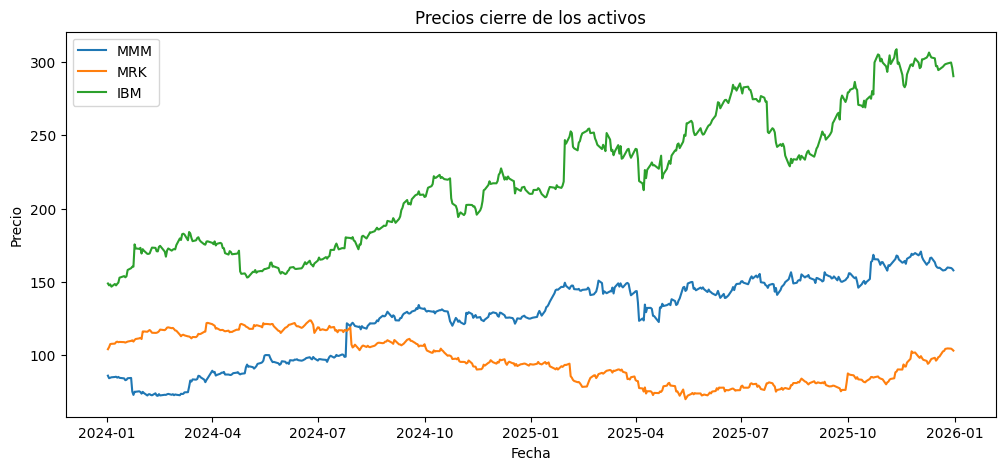

In [24]:
plt.figure(figsize=(12, 5))

for activo in activos:
    plt.plot(cierre.index, cierre[activo], label=activo)

plt.title("Precios cierre de los activos")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.show()

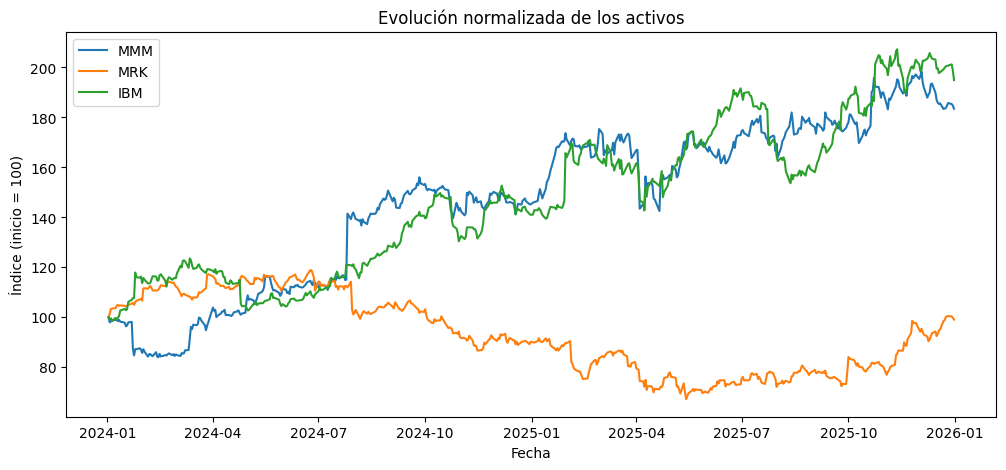

In [32]:
cierre_normalizado = cierre / cierre.iloc[0] * 100

cierre_normalizado.head()

fig, ax = plt.subplots(figsize=(12, 5))

for activo in activos:
    ax.plot(
        cierre_normalizado.index,
        cierre_normalizado[activo],
        label=activo
    )

ax.set_title("Evolución normalizada de los activos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()

plt.show()

Es mejor utilizar los precios normalizados porque permite comparar el comportamiento porcentual de los activos partiendo de una misma base. En el gráfico de precios originales, las diferencias en los valores nominales pueden dificultar la comparación. En cambio, al normalizar los precios a una base de 100, es posible identificar con mayor claridad qué activo presentó mayor crecimiento y cuáles tuvieron mayores movimientos durante el período que se analizo

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [ ]:
# 1. Calcular rendimientos

# 2. Histograma con el activo más volátil

# 3. Boxplot comparativo de rendimientos

In [34]:
rendimientos = cierre.pct_change()

rendimientos.head()

rendimientos = rendimientos.dropna()

rendimientos.head()


Ticker,IBM,MMM,MRK
Date,,,
2024-01-03,-0.008669,-0.020091,0.013511
2024-01-04,0.004747,0.003525,0.019517
2024-01-05,-0.010568,0.003883,0.001795
2024-01-08,0.012440,0.002486,0.001365
2024-01-09,-0.006578,0.002205,0.008945


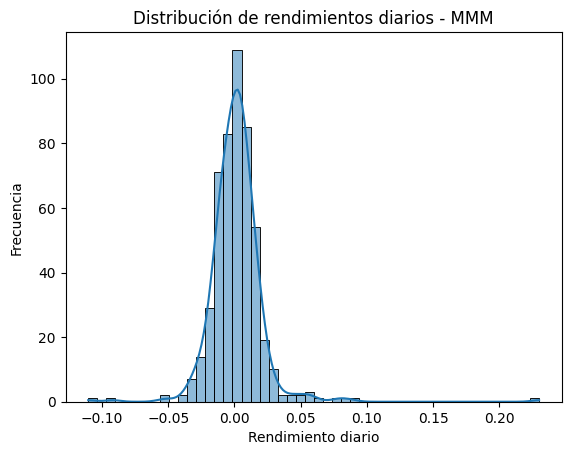

In [36]:
sns.histplot(
    data=rendimientos,
    x="MMM",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - MMM")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()

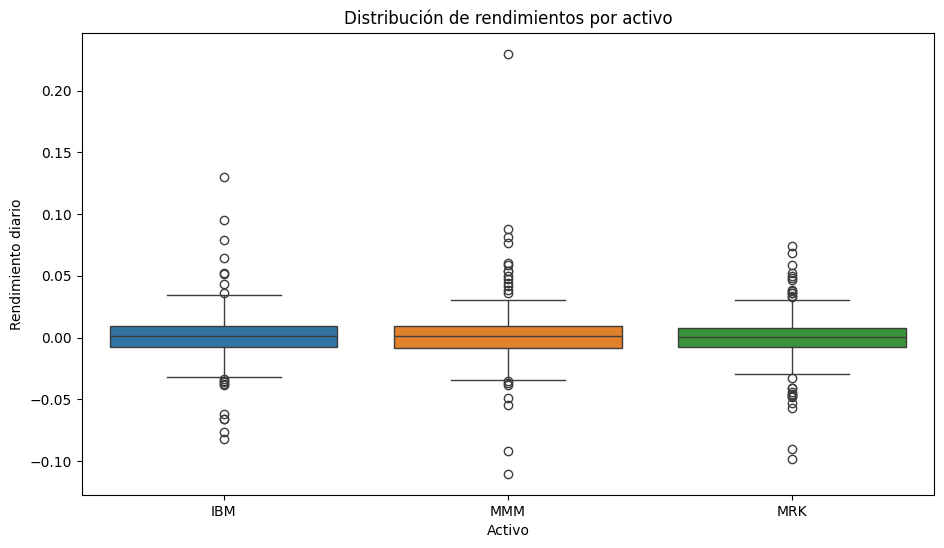

In [38]:
plt.figure(figsize=(11, 6))

sns.boxplot(data=rendimientos)

plt.title("Distribución de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")

plt.show()


**¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?**
R/ Al analizar el Boxplot, se observa que MMM presenta una dispersión ligeramente mayor en sus rendimientos diarios, veo que hay un rendimiento casi en el 0.23 positivo y otro de -11%. Esto indica que ha experimentado movimientos importantes, lo que me dice que tiene un mayor riesgo asociado a la volatilidad


**¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?**
R/Se identifican valores atípicos en los tres activos, especialmente en MMM, que presenta movimientos diarios positivos cercanos al 23% y negativos alrededor del 11%. Estos puntos representan días en los que las acciones tuvieron variaciones extraordinarias respecto a su comportamiento habitual

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

In [ ]:
# 1. Calcular matriz de correlación

# 2. Dibujar el Heatmap utilizando Seaborn

In [40]:
correlacion = rendimientos.corr()

correlacion


Ticker,IBM,MMM,MRK
Ticker,,,
IBM,1.000000,0.246800,0.131077
MMM,0.246800,1.000000,0.176682
MRK,0.131077,0.176682,1.000000


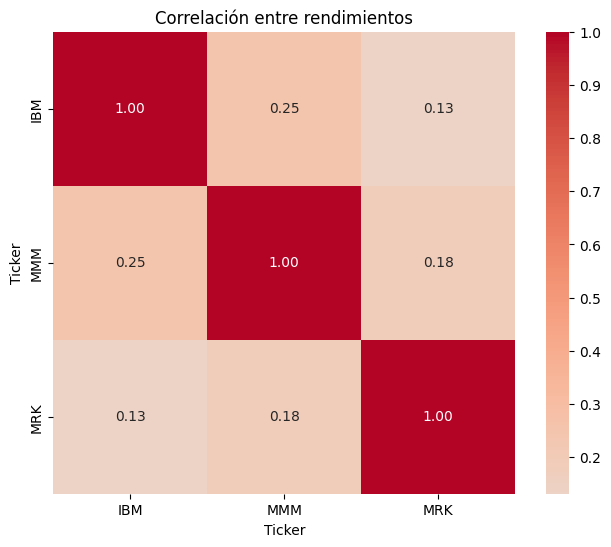

In [41]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()

**¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?**
R/No se identifica ninguna correlación fuerte entre los activos, ya que todos los valores se encuentran cercanos a cero, la correlación más alta corresponde a IBM y MMM, lo que indica una relación positiva entre sus rendimientos diarios

**Si tuvieras que armar un portafolio de inversión buscando la diversificación (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?**
R/ Eligiria IBM y MRK Porque sus rendimientos tienen una relación lineal muy débil, esto significa que los movimientos de IBM no necesariamente van acompañados de movimientos en MRK

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [42]:
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen

,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
IBM,0.001476,0.001589,0.016983,-0.082510,0.129642
MMM,0.001404,0.001237,0.019937,-0.110350,0.229906
MRK,0.000116,0.000129,0.016381,-0.098059,0.073871


En los rendimientos diarios de IBM, MMM y MRK se evidencia que IBM presentó el mayor rendimiento promedio diario, seguido de MMM y por último MRK

Sin embargo, al analizar el riesgo, MMM presentó la mayor volatilidad, con una desviación estándar del 1,9937%, además de registrar los movimientos diarios más extremos. Por otro lado, MRK mostró la menor volatilidad, con un 1,6381%, aunque también registró pérdidas significativas

En cuanto a la diversificación, IBM y MRK presentaron la menor correlación, lo que indica que sus rendimientos tienen una relación positiva muy débil

Por lo tanto, para un inversionista que busca equilibrar rentabilidad histórica y diversificación, IBM y MRK podrían ser una combinación interesante para evaluar

In [ ]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)